In [2]:
# Install required libraries
!pip install pandas numpy matplotlib seaborn plotly -q

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Set graph style
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Libraries Imported Successfully!")

Libraries Imported Successfully!


In [3]:
from google.colab import files

uploaded = files.upload()

# Read CSV file
df = pd.read_csv(next(iter(uploaded)))

# Display first five rows
print("First 5 Rows of Dataset:")
display(df.head())

Saving supermarket_grocery_sales_cleaned.csv to supermarket_grocery_sales_cleaned.csv
First 5 Rows of Dataset:


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Payment,Gross income,Rating
0,Inv-00001,B,Mandalay,Member,Male,Fashion Accessories,69.97,9,31.49,661.22,2025-02-16,Credit card,31.49,8.1
1,Inv-00002,C,Naypyitaw,Member,Male,Food And Beverages,20.96,4,4.19,88.03,2025-01-12,Cash,4.19,7.6
2,Inv-00003,C,Naypyitaw,Member,Male,Sports And Travel,53.04,10,26.52,556.92,2025-03-03,Cash,26.52,7.7
3,Inv-00004,B,Mandalay,Normal,Female,Food And Beverages,55.55,10,27.78,583.28,2025-03-21,Ewallet,27.78,9.6
4,Inv-00005,A,Yangon,Normal,Male,Electronic Accessories,30.93,6,9.28,194.86,2025-03-29,Cash,9.28,8.7


In [4]:
# Dataset shape
print("Dataset Shape:", df.shape)

# Dataset information
print("\nDataset Information:")
df.info()

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Column names
print("\nColumn Names:")
print(df.columns)

Dataset Shape: (1000, 14)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Invoice ID     1000 non-null   object 
 1   Branch         1000 non-null   object 
 2   City           1000 non-null   object 
 3   Customer type  1000 non-null   object 
 4   Gender         1000 non-null   object 
 5   Product line   1000 non-null   object 
 6   Unit price     1000 non-null   float64
 7   Quantity       1000 non-null   int64  
 8   Tax 5%         1000 non-null   float64
 9   Total          1000 non-null   float64
 10  Date           1000 non-null   object 
 11  Payment        1000 non-null   object 
 12  Gross income   1000 non-null   float64
 13  Rating         1000 non-null   float64
dtypes: float64(5), int64(1), object(8)
memory usage: 109.5+ KB

Statistical Summary:


,Unit price,Quantity,Tax 5%,Total,Gross income,Rating
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,54.668080,5.517000,15.204960,319.304860,15.204960,6.931700
std,26.290442,2.892763,11.387102,239.126638,11.387102,1.739233
min,10.020000,1.000000,0.530000,11.130000,0.530000,4.000000
25%,30.947500,3.000000,5.667500,119.062500,5.667500,5.400000
50%,55.060000,6.000000,12.425000,260.910000,12.425000,6.900000
75%,77.365000,8.000000,22.645000,475.592500,22.645000,8.500000
max,99.970000,10.000000,49.820000,1046.320000,49.820000,10.000000



Column Names:
Index(['Invoice ID', 'Branch', 'City', 'Customer type', 'Gender',
       'Product line', 'Unit price', 'Quantity', 'Tax 5%', 'Total', 'Date',
       'Payment', 'Gross income', 'Rating'],
      dtype='object')


In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

# Remove duplicate records
df = df.drop_duplicates()

# Convert date column
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Remove missing values
df = df.dropna(subset=['Date', 'Total', 'Product line'])

print("Data Cleaning Completed!")

# Display cleaned dataset
display(df.head())

Missing Values:
Invoice ID       0
Branch           0
City             0
Customer type    0
Gender           0
Product line     0
Unit price       0
Quantity         0
Tax 5%           0
Total            0
Date             0
Payment          0
Gross income     0
Rating           0
dtype: int64
Data Cleaning Completed!


,Invoice ID,Branch,City,Customer type,Gender,Product line,Unit price,Quantity,Tax 5%,Total,Date,Payment,Gross income,Rating
0,Inv-00001,B,Mandalay,Member,Male,Fashion Accessories,69.97,9,31.49,661.22,2025-02-16,Credit card,31.49,8.1
1,Inv-00002,C,Naypyitaw,Member,Male,Food And Beverages,20.96,4,4.19,88.03,2025-01-12,Cash,4.19,7.6
2,Inv-00003,C,Naypyitaw,Member,Male,Sports And Travel,53.04,10,26.52,556.92,2025-03-03,Cash,26.52,7.7
3,Inv-00004,B,Mandalay,Normal,Female,Food And Beverages,55.55,10,27.78,583.28,2025-03-21,Ewallet,27.78,9.6
4,Inv-00005,A,Yangon,Normal,Male,Electronic Accessories,30.93,6,9.28,194.86,2025-03-29,Cash,9.28,8.7


In [6]:
# Calculate total sales
total_sales = df['Total'].sum()

# Calculate total quantity
total_quantity = df['Quantity'].sum()

# Calculate average sales
average_sales = df['Total'].mean()

# Display results
print("========== SALES ANALYSIS ==========")
print("Total Sales:", round(total_sales, 2))
print("Total Quantity Sold:", total_quantity)
print("Average Sales:", round(average_sales, 2))
print("Total Transactions:", len(df))

========== SALES ANALYSIS ==========
Total Sales: 319304.86
Total Quantity Sold: 5517
Average Sales: 319.3
Total Transactions: 1000


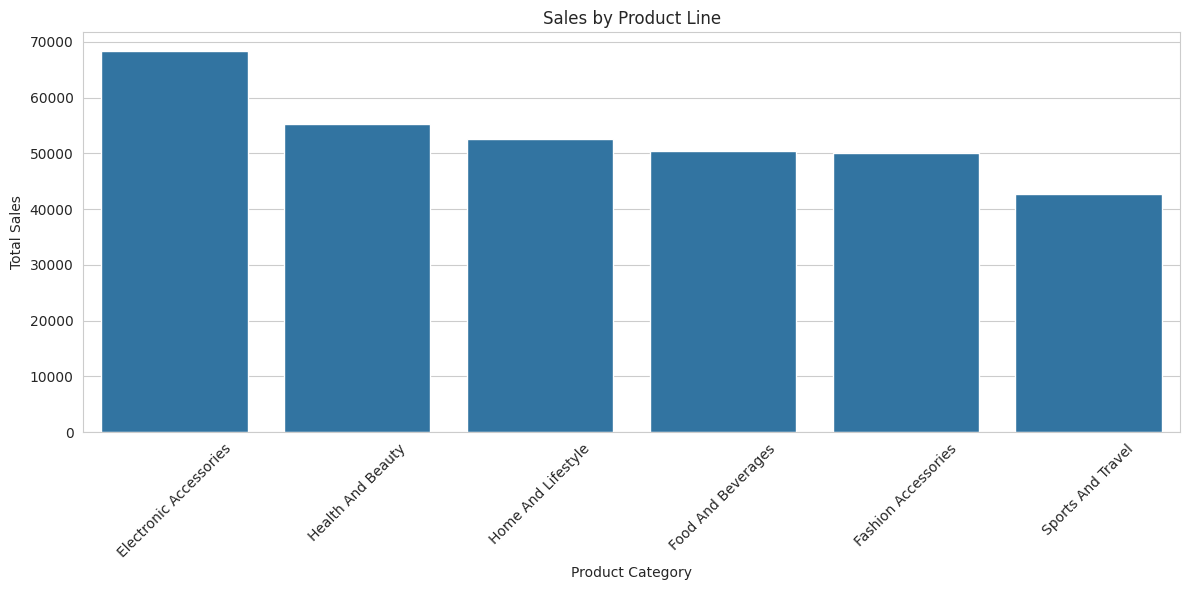

In [7]:
plt.figure(figsize=(12,6))

product_sales = df.groupby('Product line')['Total'].sum().sort_values(ascending=False)

sns.barplot(
    x=product_sales.index,
    y=product_sales.values
)

plt.title("Sales by Product Line")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

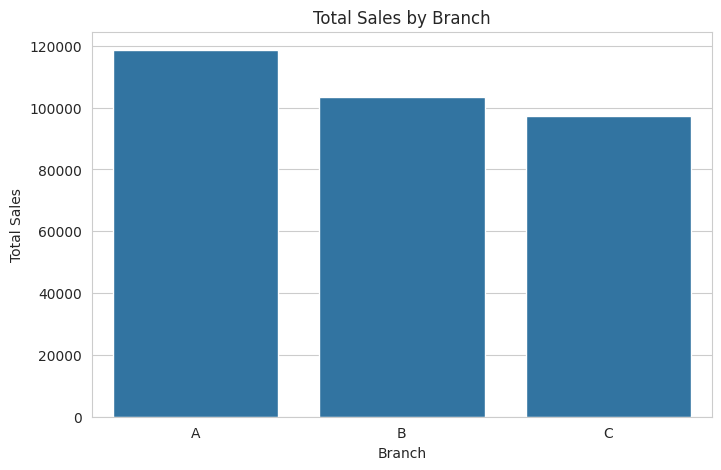

In [8]:
plt.figure(figsize=(8,5))

branch_sales = df.groupby('Branch')['Total'].sum()

sns.barplot(
    x=branch_sales.index,
    y=branch_sales.values
)

plt.title("Total Sales by Branch")
plt.xlabel("Branch")
plt.ylabel("Total Sales")

plt.show()

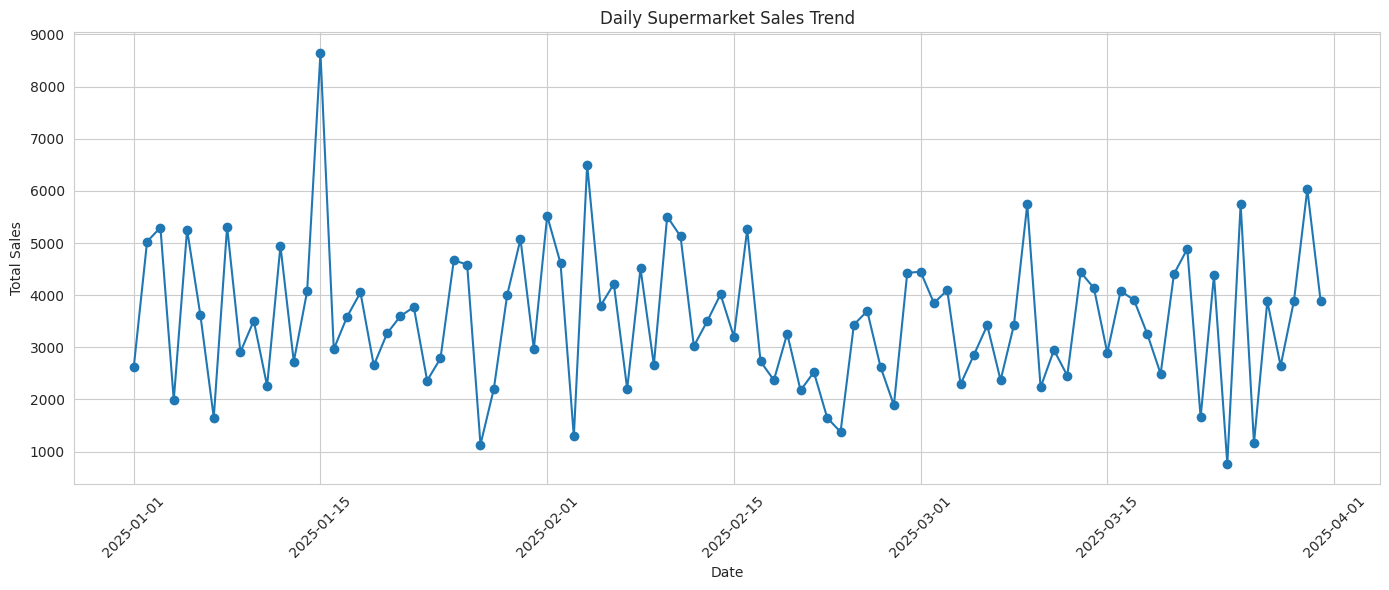

In [9]:
plt.figure(figsize=(14,6))

daily_sales = df.groupby('Date')['Total'].sum()

plt.plot(
    daily_sales.index,
    daily_sales.values,
    marker='o'
)

plt.title("Daily Supermarket Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Sales")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

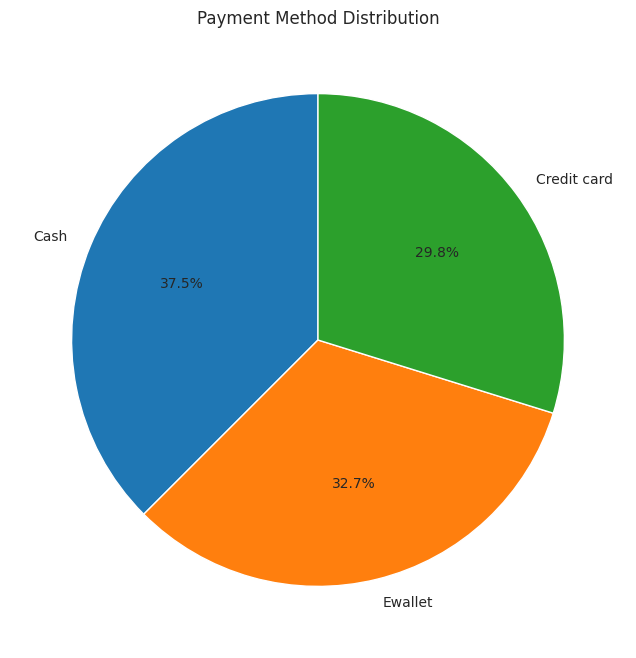

In [10]:
payment_count = df['Payment'].value_counts()

plt.figure(figsize=(8,8))

plt.pie(
    payment_count.values,
    labels=payment_count.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title("Payment Method Distribution")

plt.show()

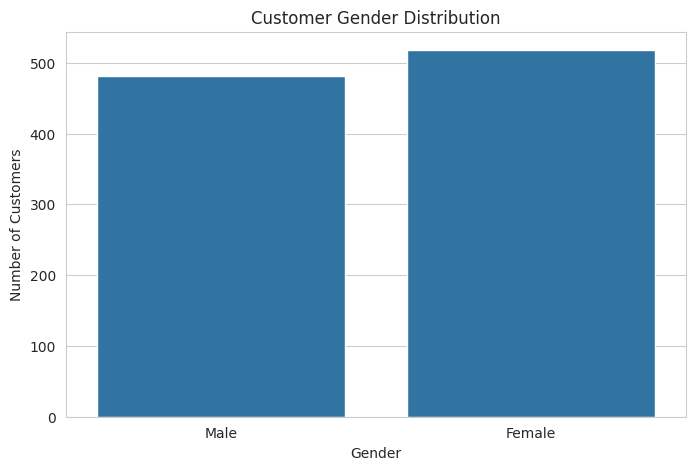

In [11]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x='Gender'
)

plt.title("Customer Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

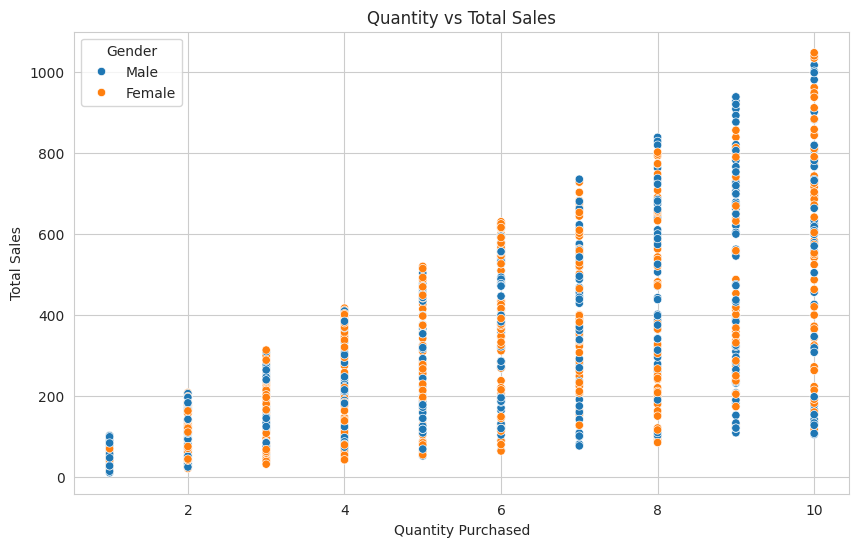

In [12]:
plt.figure(figsize=(10,6))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total',
    hue='Gender'
)

plt.title("Quantity vs Total Sales")
plt.xlabel("Quantity Purchased")
plt.ylabel("Total Sales")

plt.show()

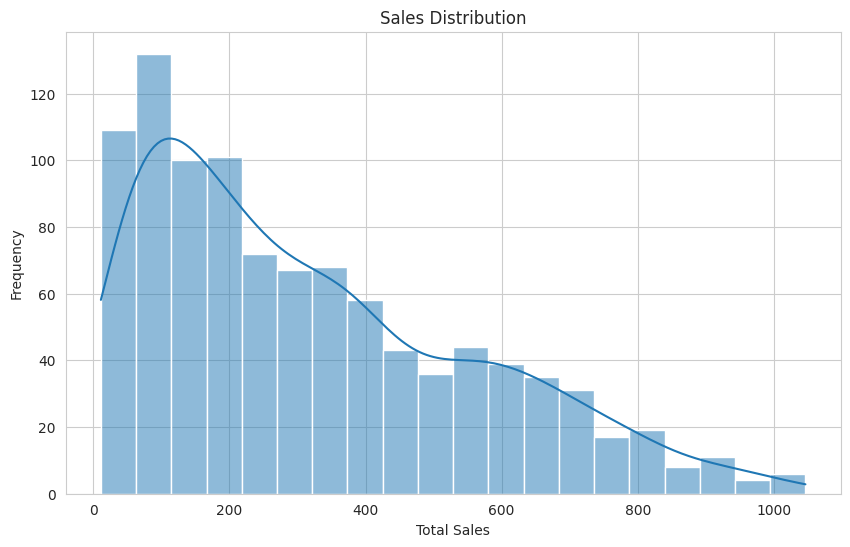

In [13]:
plt.figure(figsize=(10,6))

sns.histplot(
    df['Total'],
    bins=20,
    kde=True
)

plt.title("Sales Distribution")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")

plt.show()

In [14]:
product_data = df.groupby('Product line', as_index=False)['Total'].sum()

fig = px.bar(
    product_data,
    x='Product line',
    y='Total',
    color='Product line',
    title='Interactive Supermarket Product Sales Analysis',
    text_auto='.2s'
)

fig.update_layout(
    xaxis_title="Product Category",
    yaxis_title="Total Sales"
)

fig.show()

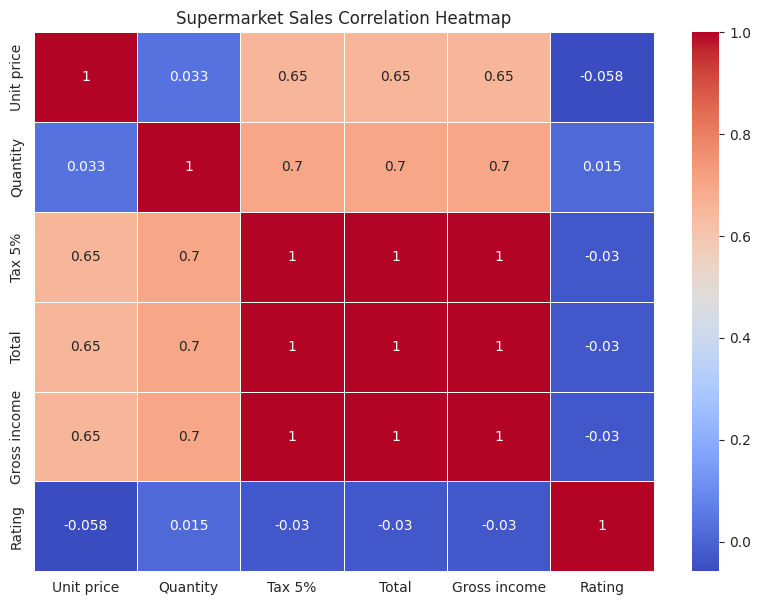

In [15]:
plt.figure(figsize=(10,7))

numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    linewidths=0.5
)

plt.title("Supermarket Sales Correlation Heatmap")

plt.show()

In [16]:
print("========== FINAL EDA RESULTS ==========")

print("\n1. Highest Selling Product:")
print(df.groupby('Product line')['Total'].sum().idxmax())

print("\n2. Best Performing Branch:")
print(df.groupby('Branch')['Total'].sum().idxmax())

print("\n3. Most Used Payment Method:")
print(df['Payment'].mode()[0])

print("\n4. Total Revenue:")
print(round(df['Total'].sum(), 2))

print("\n5. Total Products Sold:")
print(df['Quantity'].sum())

print("\n6. Average Customer Rating:")
if 'Rating' in df.columns:
    print(round(df['Rating'].mean(), 2))
else:
    print("Rating column not available")

print("\nEDA Analysis Completed Successfully!")

========== FINAL EDA RESULTS ==========

1. Highest Selling Product:
Electronic Accessories

2. Best Performing Branch:
A

3. Most Used Payment Method:
Cash

4. Total Revenue:
319304.86

5. Total Products Sold:
5517

6. Average Customer Rating:
6.93

EDA Analysis Completed Successfully!
